# Smart Battery Manager - TinyML per Attuatore IoT
**Progetto IoT 2026** - Gruppo: Leonardo Lentini, Dario Falaschi

Questo notebook prepara i dati di generazione solare, bilancia il dataset con SMOTE, addestra una Rete Neurale (Keras) per prevedere crolli imminenti di potenza e converte il modello in codice C tramite `emlearn`.

### 1. Caricamento e Preparazione Dati
*Assicurati di aver caricato nel pannello file a sinistra i file `Plant_Generation_Data.csv` e `Plant_Weather_Sensor_Data.csv` (per entrambi i Plant 1 e 2) scaricati da Kaggle.*

In [ ]:
import pandas as pd
import numpy as np

# --- ELABORAZIONE PLANT 1 ---
df_gen_1 = pd.read_csv('Plant_1_Generation_Data.csv')
df_weather_1 = pd.read_csv('Plant_1_Weather_Sensor_Data.csv')

df_gen_1['DATE_TIME'] = pd.to_datetime(df_gen_1['DATE_TIME'], format='%d-%m-%Y %H:%M')
df_weather_1['DATE_TIME'] = pd.to_datetime(df_weather_1['DATE_TIME'])

inverter_id_1 = df_gen_1['SOURCE_KEY'].unique()[0]
df_gen_filtered_1 = df_gen_1[df_gen_1['SOURCE_KEY'] == inverter_id_1].copy()

df_merged_1 = pd.merge(df_gen_filtered_1, df_weather_1, on='DATE_TIME', how='inner')
colonne_utili = ['DATE_TIME', 'AC_POWER', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']
df_1 = df_merged_1[colonne_utili].sort_values('DATE_TIME').reset_index(drop=True)


# --- ELABORAZIONE PLANT 2 ---
df_gen_2 = pd.read_csv('Plant_2_Generation_Data.csv')
df_weather_2 = pd.read_csv('Plant_2_Weather_Sensor_Data.csv')

# Il Plant 2 usa un formato data diverso (spesso Anno-Mese-Giorno)
df_gen_2['DATE_TIME'] = pd.to_datetime(df_gen_2['DATE_TIME'])
df_weather_2['DATE_TIME'] = pd.to_datetime(df_weather_2['DATE_TIME'])

inverter_id_2 = df_gen_2['SOURCE_KEY'].unique()[0]
df_gen_filtered_2 = df_gen_2[df_gen_2['SOURCE_KEY'] == inverter_id_2].copy()

df_merged_2 = pd.merge(df_gen_filtered_2, df_weather_2, on='DATE_TIME', how='inner')
df_2 = df_merged_2[colonne_utili].sort_values('DATE_TIME').reset_index(drop=True)


# --- UNIONE DEI DUE IMPIANTI ---
# Concateniamo i due dataframe uno sotto l'altro
df = pd.concat([df_1, df_2], ignore_index=True)

print(f"Righe Plant 1: {len(df_1)}")
print(f"Righe Plant 2: {len(df_2)}")
print(f"Righe Totali per l'addestramento: {len(df)}")
df.head()

Righe Plant 1: 3154
Righe Plant 2: 3195
Righe Totali per l'addestramento: 6349


,DATE_TIME,AC_POWER,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,0.0,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,0.0,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,0.0,24.935753,22.592306,0.0
3,2020-05-15 00:45:00,0.0,24.846130,22.360852,0.0
4,2020-05-15 01:00:00,0.0,24.621525,22.165423,0.0


### 2. Feature Engineering (Logica temporale e Target)

In [ ]:
# Creazione variabili storiche (15 minuti fa)
df['AC_POWER_t-1'] = df['AC_POWER'].shift(1)
df['IRRADIATION_t-1'] = df['IRRADIATION'].shift(1)

# Creazione variabile target (Potenza tra 15 minuti)
df['AC_POWER_t+1'] = df['AC_POWER'].shift(-1)

# Calcolo del crollo: Drop percentuale tra ora e il passo successivo
drop_percentuale = (df['AC_POWER'] - df['AC_POWER_t+1']) / (df['AC_POWER'] + 0.0001)

# Label = 1 se la potenza cala del 30% e stavamo producendo più di 100kW
df['Condition'] = np.where((drop_percentuale > 0.30) & (df['AC_POWER'] > 100), 1, 0)

# Rimuoviamo i NaN generati dallo shift e le colonne che non daremo in input
df = df.dropna()
df = df[['Condition', 'AC_POWER', 'AC_POWER_t-1', 'IRRADIATION', 'IRRADIATION_t-1', 'MODULE_TEMPERATURE']]

CLASS_NAMES = ['Stabile', 'Crollo Imminente']
print('Distribuzione delle Classi originali:')
print(df['Condition'].value_counts())
df.head()

Distribuzione delle Classi originali:
Condition
0    6001
1     346
Name: count, dtype: int64


,Condition,AC_POWER,AC_POWER_t-1,IRRADIATION,IRRADIATION_t-1,MODULE_TEMPERATURE
1,0,0.0,0.0,0.0,0.0,22.761668
2,0,0.0,0.0,0.0,0.0,22.592306
3,0,0.0,0.0,0.0,0.0,22.360852
4,0,0.0,0.0,0.0,0.0,22.165423
5,0,0.0,0.0,0.0,0.0,21.968571


### 3. Preparazione Arrays e Split Dati

In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np

# Separiamo target e features
labels_1d = np.array(df.pop('Condition'))
features = np.array(df)

# Divisione 85% Train, 15% Test (come da notebook di Vallati)
train_features, test_features, train_labels_1d, test_labels_1d = train_test_split(
    features, labels_1d, test_size=0.15, shuffle=True, random_state=42, stratify=labels_1d
)

### 4. Normalizzazione (Cruciale per i dispositivi IoT)
Esportiamo le costanti C da incollare nel firmware dell'Attuatore in Cooja.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
# Fit solo sul train per evitare data leakage
train_features = scaler.fit_transform(train_features)
test_features  = scaler.transform(test_features)

print('=== COPIA QUESTE COSTANTI NEL TUO FIRMWARE C (ml_model.c) ===')
print(f'static const float FEATURE_MEAN[5]  = ' \
      f'{{ {scaler.mean_[0]:.4f}f, {scaler.mean_[1]:.4f}f, {scaler.mean_[2]:.4f}f, {scaler.mean_[3]:.4f}f, {scaler.mean_[4]:.4f}f }};')
print(f'static const float FEATURE_SCALE[5] = ' \
      f'{{ {scaler.scale_[0]:.4f}f, {scaler.scale_[1]:.4f}f, {scaler.scale_[2]:.4f}f, {scaler.scale_[3]:.4f}f, {scaler.scale_[4]:.4f}f }};')
print('/* Ordine: AC_POWER, AC_POWER_t-1, IRRADIATION, IRRADIATION_t-1, MODULE_TEMPERATURE */')

=== COPIA QUESTE COSTANTI NEL TUO FIRMWARE C (ml_model.c) ===
static const float FEATURE_MEAN[5]  = { 276.5014f, 276.9828f, 0.2314f, 0.2313f, 32.0125f };
static const float FEATURE_SCALE[5] = { 380.8638f, 381.0449f, 0.3070f, 0.3065f, 11.8554f };
/* Ordine: AC_POWER, AC_POWER_t-1, IRRADIATION, IRRADIATION_t-1, MODULE_TEMPERATURE */


### 5. SMOTE: Bilanciamento Sintetico del Dataset
Dato che i crolli sono rari, usiamo SMOTE per generare crolli sintetici e riequilibrare il train set 50/50. Questo permetterà alla Rete Neurale di non "ignorare" i blackout.

In [ ]:
!pip install imbalanced-learn
from imblearn.over_sampling import SMOTE
from keras.utils import to_categorical

smote = SMOTE(random_state=42)
# Applichiamo SMOTE SOLO ai dati di addestramento
train_features_sm, train_labels_sm_1d = smote.fit_resample(train_features, train_labels_1d)

print("\nDistribuzione Classi PRIMA di SMOTE:", np.bincount(train_labels_1d))
print("Distribuzione Classi DOPO SMOTE:", np.bincount(train_labels_sm_1d))

# Riconvertiamo in One-Hot encoding per Keras
train_labels_sm = to_categorical(train_labels_sm_1d)
test_labels = to_categorical(test_labels_1d)


Distribuzione Classi PRIMA di SMOTE: [5100  294]
Distribuzione Classi DOPO SMOTE: [5100 5100]


### 6. Costruzione Rete Neurale per Microcontrollori

In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import Dense, Input

NB_classes  = 2   # Stabile (0) o Crollo (1)
NB_features = 5   # Le nostre 5 feature ambientali/elettriche

# Rete potenziata (32 neuroni) per comprendere i pattern complessi di SMOTE
model = tf.keras.Sequential([
    Input(shape=(NB_features,)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(NB_classes, activation='softmax'),
])

# Riduciamo leggermente il learning rate per un apprendimento più stabile
optimizer = tf.keras.optimizers.Adam(learning_rate=0.0005)

model.compile(optimizer=optimizer,
              loss=tf.keras.losses.categorical_crossentropy,
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 754 (2.95 KB)

 Trainable params: 754 (2.95 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_loss', patience=15,
                           restore_best_weights=True, verbose=1)

# SMOTE ha già bilanciato i dati 50/50, quindi non usiamo class_weight aggressivi
history = model.fit(
    x=train_features_sm,
    y=train_labels_sm,
    epochs=150,
    validation_data=(test_features, test_labels),
    callbacks=[early_stop],
    verbose=1,
    shuffle=True
)

Epoch 1/150
319/319 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.7170 - loss: 0.5238 - val_accuracy: 0.6495 - val_loss: 0.4501
Epoch 2/150
319/319 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7893 - loss: 0.4331 - val_accuracy: 0.6548 - val_loss: 0.4514
Epoch 3/150
319/319 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7938 - loss: 0.4084 - val_accuracy: 0.6516 - val_loss: 0.4579
Epoch 4/150
319/319 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7993 - loss: 0.3993 - val_accuracy: 0.6548 - val_loss: 0.4475
Epoch 5/150
319/319 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8037 - loss: 0.3924 - val_accuracy: 0.6548 - val_loss: 0.4443
Epoch 6/150
319/319 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8064 - loss: 0.3875 - val_accuracy: 0.6621 - val_loss: 0.4233
Epoch 7/150
319/319 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8078 - loss: 0.3833 - val_accuracy: 0.6590 - val_loss: 0.4711
Epoch 8/150
319/319 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8118 - loss: 0.3792 - val_accu

### 7. Valutazione Definitiva (Precisione e Recall)

30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

=== REPORT DI CLASSIFICAZIONE POST-SMOTE ===
                  precision    recall  f1-score   support

         Stabile       0.99      0.69      0.81       901
Crollo Imminente       0.14      0.85      0.23        52

        accuracy                           0.70       953
       macro avg       0.56      0.77      0.52       953
    weighted avg       0.94      0.70      0.78       953



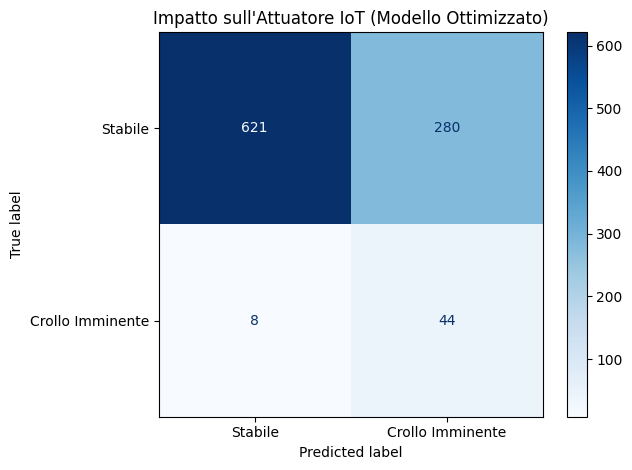

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

y_pred = model.predict(test_features).argmax(axis=1)
y_true = test_labels.argmax(axis=1)

print("\n=== REPORT DI CLASSIFICAZIONE POST-SMOTE ===")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred,
    display_labels=CLASS_NAMES,
    cmap='Blues'
)
plt.title('Impatto sull\'Attuatore IoT (Modello Ottimizzato)')
plt.tight_layout()
plt.show()

### 8. Conversione del Modello per l'IoT con Emlearn

In [ ]:
!pip install emlearn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.5/78.5 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 314.2/314.2 kB 14.6 MB/s eta 0:00:00


In [ ]:
import emlearn
import os

path = 'smart_battery_model.h'

# Converte la rete neurale Keras in un file .h inline per il compilatore C
cmodel = emlearn.convert(model, method='inline')
cmodel.save(file=path, name='smart_battery')

size_bytes = os.path.getsize(path)
nrf52840_ram = 256 * 1024  # bytes

print(f'Modello salvato in: {path}')
print(f'Dimensione file C: {size_bytes / 1024:.1f} KB ({size_bytes:,} bytes)')
print(f'Uso della RAM del dongle: {size_bytes / nrf52840_ram * 100:.2f}%')

Modello salvato in: smart_battery_model.h
Dimensione file C: 9.9 KB (10,099 bytes)
Uso della RAM del dongle: 3.85%


#Generazione blocchi di dati come file .h

In [ ]:
# Troviamo l'indice del primo crollo usando labels_1d (visto che df.pop l'ha rimossa dal dataframe)
indice_crollo = np.where(labels_1d == 1)[0][0]

inizio = max(0, indice_crollo - 10) # Prendiamo 10 passi prima del crollo
fine = inizio + 50
df_replay = df.iloc[inizio:fine]

# Generiamo il testo in linguaggio C
c_header = "/* File generato automaticamente da Python - Dataset di Replay */\n\n"
c_header += f"#define REPLAY_STEPS {len(df_replay)}\n\n"

# Array Potenza
ac_power_vals = ", ".join([f"{x:.2f}" for x in df_replay['AC_POWER']])
c_header += f"float ac_power_array[REPLAY_STEPS] = {{{ac_power_vals}}};\n\n"

# Array Irraggiamento
irr_vals = ", ".join([f"{x:.4f}" for x in df_replay['IRRADIATION']])
c_header += f"float irradiation_array[REPLAY_STEPS] = {{{irr_vals}}};\n\n"

# Array Temperatura Modulo
temp_vals = ", ".join([f"{x:.2f}" for x in df_replay['MODULE_TEMPERATURE']])
c_header += f"float module_temp_array[REPLAY_STEPS] = {{{temp_vals}}};\n\n"

# Salviamo il file
with open('dataset_replay.h', 'w') as f:
    f.write(c_header)

print("File 'dataset_replay.h' generato con successo! Scaricalo dal pannello a sinistra e mettilo nella cartella di Cooja.")

File 'dataset_replay.h' generato con successo! Scaricalo dal pannello a sinistra e mettilo nella cartella di Cooja.
